<a href="https://colab.research.google.com/github/amirulhaq411/PeluangMath/blob/main/Team%20Based%20Project%20Muhammad%20AMirul%20Haq%20dan%20Adi%20Janes%20Ngingi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **TEAM BASED PROJECT REPORT**

Nama Mahasiswa : Adi Janes Ngingi (25031140036), Muhammad Amirul Haq Burhany (25031140040)

Data Set : Hasil Asesmen Guru Tahun 2021 (https://data.kemendikdasmen.go.id/dataset/p/asesmen-nasional-truqp/rapor-publik-asesmen-nasional-2025-guru-2025-sd-mi-sederajat)

Sumber : Portal Data kemendikdasmen (https://data.kemendikdasmen.go.id)

# **Identifikasi Masalah dan Deskripsi Dataset**

Jelaskan secara singkat: Masalah yang ditemui dalam data set ini melihat hasil asesmen guru yang dilakukan pada tahun 2021 oleh kementrian pendidikan secara nasional
Permasalahan pendidikan yang ingin dikaji. Permasalahan yang ingin dikaji ialah melihat tingkat kemampuan guru dalam mengelola lingkungan sekolah dalam pembelajaran
Tujuan analisis. Melihat korelasi terhadap lingkungan sekolah/ekosistem sekolah terhadap pembeljaran
Sumber dataset. Portal Data kemendikdasmen (https://data.kemendikdasmen.go.id)
Jumlah observasi dan variabel. 3000 data dan 7 Varibel
Deskripsi variabel prediktor dan variabel target. Varibel Prediktor : CAF Varibel Target : ACH, AIN, AKC, APC, APK, BCP

In [ ]:

#1. IMPORT LIBRARY

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [ ]:
# 2. MEMUAT DATA & MEMBUAT KOLOM "Perlu Perhatian"
FILE = "/content/drive/MyDrive/Machine Learning/Dataset Bersih Ass Guru 25.csv"

df = pd.read_csv(FILE)

fitur = ["ACH", "AIN", "AKC", "APC", "APK", "BCP", "CAF"]

# Kolom bantu (tidak dipakai sebagai fitur)
df["rata_rata"] = df[fitur].mean(axis=1)

# Aturan target
df["Perlu Perhatian"] = (
    (df["rata_rata"] < 60) | (df[fitur].min(axis=1) < 40)
).astype(int)

display(df.head())
print("Ukuran data:", df.shape)
print("\nJumlah setiap kelas:")
print(
    df["Perlu Perhatian"]
    .value_counts()
    .rename(index={0: "Tidak", 1: "Ya"})
)

,kd_guru_an,ACH,AIN,AKC,APC,APK,BCP,CAF,rata_rata,Perlu Perhatian
0,25-1113662-20142784,82.05,57.11,64.74,NaN,64.08,46.04,NaN,62.804000,0
1,25-1119387-20657546,82.05,74.81,92.97,NaN,58.60,78.50,NaN,77.386000,0
2,25-1119387-20657638,86.18,78.36,99.48,44.64,88.85,85.34,69.19,78.862857,0
3,25-1119387-20667109,74.90,NaN,97.93,34.98,NaN,47.05,88.98,68.768000,1
4,25-1119387-20667114,82.05,70.02,92.97,NaN,81.66,78.50,NaN,81.040000,0


Ukuran data: (283948, 10)

Jumlah setiap kelas:
Perlu Perhatian
Tidak    148960
Ya       134988
Name: count, dtype: int64


In [ ]:
# Melihat isi data
## shape:melihat jumlah data
print(df.shape)

(283948, 10)


In [ ]:
# Mengidentifikasi tipe data setiap variabel
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 283948 entries, 0 to 283947
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   kd_guru_an       283948 non-null  object 
 1   ACH              283756 non-null  float64
 2   AIN              189007 non-null  float64
 3   AKC              283674 non-null  float64
 4   APC              186687 non-null  float64
 5   APK              186274 non-null  float64
 6   BCP              283258 non-null  float64
 7   CAF              189182 non-null  float64
 8   rata_rata        283867 non-null  float64
 9   Perlu Perhatian  283948 non-null  int64  
dtypes: float64(8), int64(1), object(1)
memory usage: 21.7+ MB


In [ ]:
# Mengidentifikasi tipe data setiap variabel
print(df.dtypes)

kd_guru_an          object
ACH                float64
AIN                float64
AKC                float64
APC                float64
APK                float64
BCP                float64
CAF                float64
rata_rata          float64
Perlu Perhatian      int64
dtype: object


In [ ]:
# --- PENANGANAN MASALAH DATA ---

# Hitung ulang duplicate_rows untuk menghindari NameError jika sel sebelumnya belum dieksekusi
duplicate_rows = df.duplicated().sum()

# A. Menangani data duplikat (jika ada)
if duplicate_rows > 0:
    df = df.drop_duplicates()
    print(f"Data duplikat berhasil dihapus. Jumlah data sekarang: {df.shape[0]} baris.")
else:
    print("Tidak ada data duplikat yang perlu dihapus.")

# B. Menangani missing values (jika ada)
# Mengisi nilai kosong pada kolom numerik dengan nilai rata-rata (mean) masing-masing kolom
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        mean_value = df[col].mean()
        df[col] = df[col].fillna(mean_value)
        print(f"Nilai kosong pada kolom '{col}' berhasil diisi dengan nilai rata-rata ({mean_value:.2f}).")

print("\nProses pemeriksaan dan pembersihan data selesai!")

Tidak ada data duplikat yang perlu dihapus.
Nilai kosong pada kolom 'ACH' berhasil diisi dengan nilai rata-rata (64.83).
Nilai kosong pada kolom 'AIN' berhasil diisi dengan nilai rata-rata (64.96).
Nilai kosong pada kolom 'AKC' berhasil diisi dengan nilai rata-rata (75.43).
Nilai kosong pada kolom 'APC' berhasil diisi dengan nilai rata-rata (50.15).
Nilai kosong pada kolom 'APK' berhasil diisi dengan nilai rata-rata (66.66).
Nilai kosong pada kolom 'BCP' berhasil diisi dengan nilai rata-rata (61.09).
Nilai kosong pada kolom 'CAF' berhasil diisi dengan nilai rata-rata (68.70).
Nilai kosong pada kolom 'rata_rata' berhasil diisi dengan nilai rata-rata (65.03).

Proses pemeriksaan dan pembersihan data selesai!


In [ ]:
# Menghitung statistik deskriptif untuk variabel numerik
numeric_desc = df.describe().T

# Menambahkan nilai median secara eksplisit ke dalam tabel statistik deskriptif
numeric_desc['median'] = df.select_dtypes(include=['float64', 'int64']).median()

# Menyusun ulang urutan kolom agar lebih mudah dibaca
numeric_desc = numeric_desc[['count', 'mean', 'median', 'std', 'min', 'max']]

print("Statistik Deskriptif Variabel Numerik:")
display(numeric_desc)

Statistik Deskriptif Variabel Numerik:


,count,mean,median,std,min,max
ACH,283756.0,64.833560,67.037300,15.317713,5.87770,86.1800
AIN,189007.0,64.962235,61.746600,13.368171,10.81900,100.0000
AKC,283674.0,75.425838,72.492300,15.127062,0.00000,99.4831
APC,186687.0,50.146304,44.637700,17.358878,0.00000,96.1400
APK,186274.0,66.662396,62.476400,16.348512,2.17390,100.0000
BCP,283258.0,61.092485,60.323000,15.764866,0.00000,96.0000
CAF,189182.0,68.700571,66.666500,17.969689,0.00010,100.0000
rata_rata,283867.0,65.033315,63.352629,11.497855,13.67485,95.2340
Perlu Perhatian,283948.0,0.475397,0.000000,0.499395,0.00000,1.0000


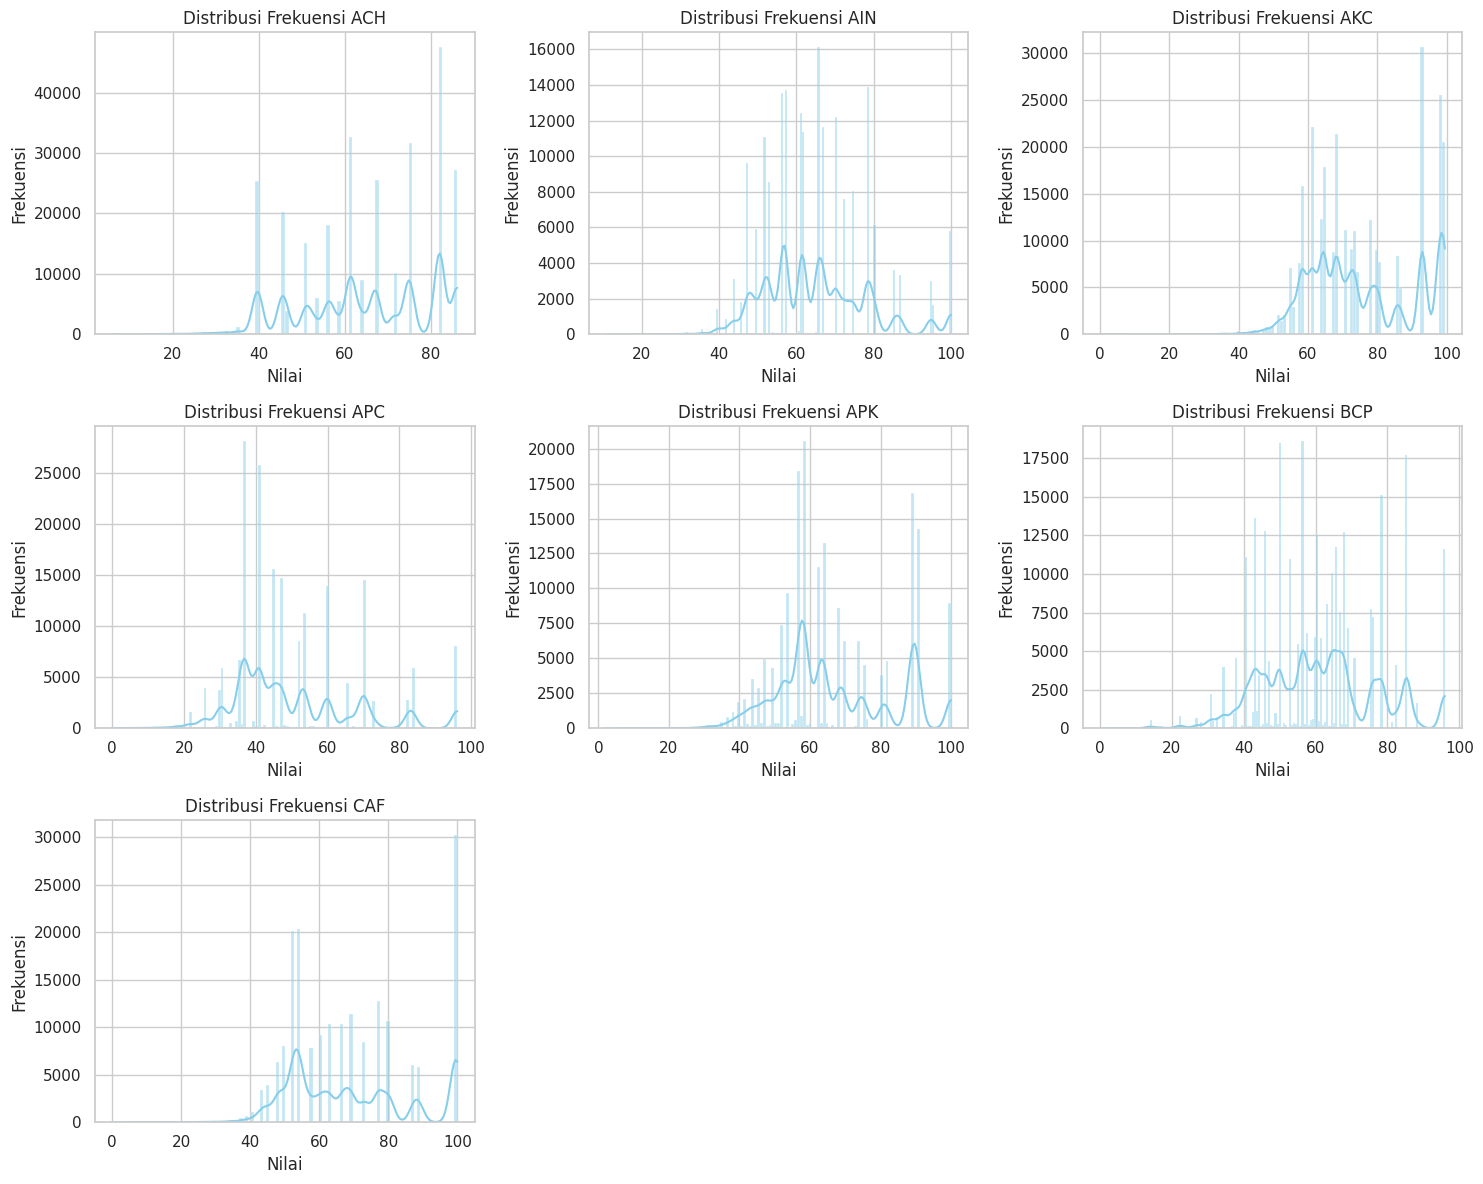

In [ ]:
# Memilih kolom numerik saja (menghindari kd_guru_an)
numeric_cols = ['ACH', 'AIN', 'AKC', 'APC', 'APK', 'BCP', 'CAF']

# Mengatur tata letak subplot untuk histogram
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribusi Frekuensi {col}')
    axes[i].set_xlabel('Nilai')
    axes[i].set_ylabel('Frekuensi')

# Menghapus subplot kosong yang tersisa
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================
# 3. MENENTUKAN FITUR DAN TARGET
# =========================================================
X = df[fitur]
y = df["Perlu Perhatian"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

Jumlah data train: 227158
Jumlah data test : 56790


Nilai Korelasi Pearson antara Prediktor dengan Variabel Target:
ACH   -0.627718
AIN   -0.493268
AKC   -0.517203
APC   -0.639124
APK   -0.553869
BCP   -0.388490


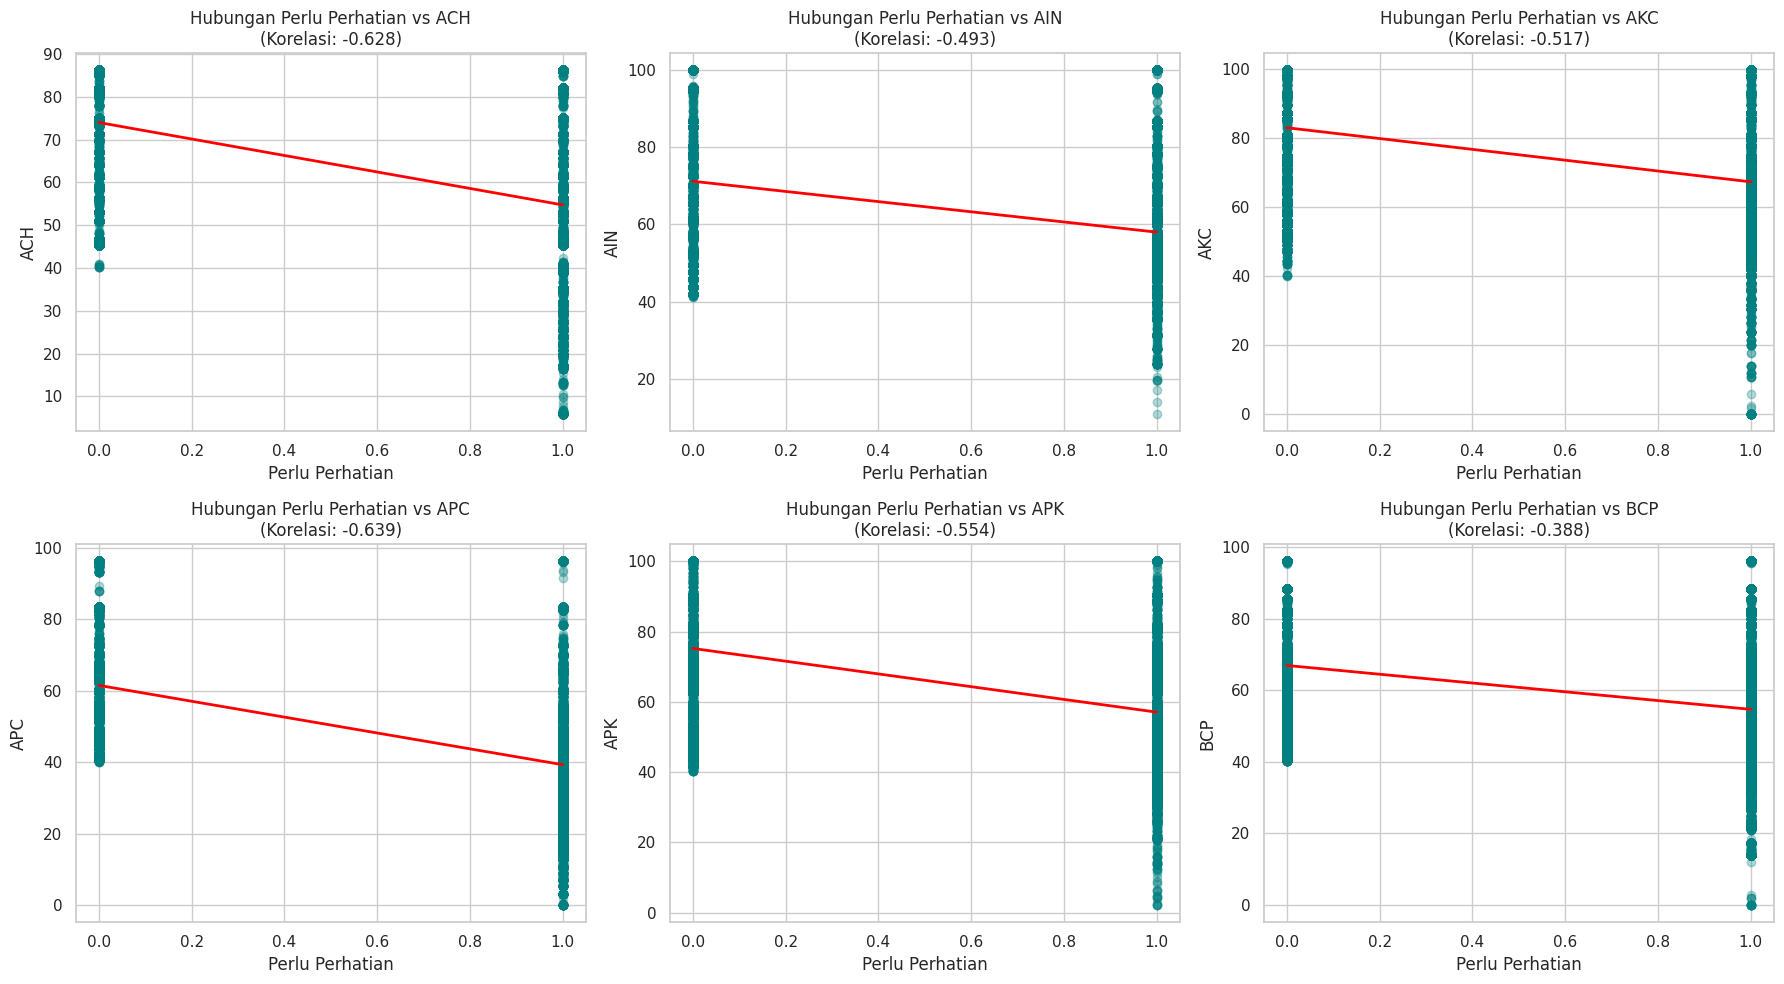

In [ ]:
# Menghitung nilai korelasi Pearson antara Perlu Perhatian dan seluruh variabel target
targets = ['ACH', 'AIN', 'AKC', 'APC', 'APK', 'BCP']
predictor = 'Perlu Perhatian'

correlations = df[[predictor] + targets].corr()[predictor].drop(predictor)
print("Nilai Korelasi Pearson antara Prediktor dengan Variabel Target:")
print(correlations.to_string())

#Visualisasi hubungan menggunakan Scatter Plot dengan garis regresi
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()

for i, target in enumerate(targets):
    sns.regplot(data=df, x=predictor, y=target, ax=axes[i],
                scatter_kws={'alpha': 0.3, 'color': 'teal'},
                line_kws={'color': 'red', 'linewidth': 2})

    corr_value = correlations[target]
    axes[i].set_title(f'Hubungan {predictor} vs {target}\n(Korelasi: {corr_value:.3f})')
    axes[i].set_xlabel(predictor)
    axes[i].set_ylabel(target)

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================
# 4. PIPELINE SCALING + KNN (k = 7)
# =========================================================
model_knn = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7)),
])

model_knn.fit(X_train, y_train)
pred_knn = model_knn.predict(X_test)
print("Model selesai dilatih.")

Model selesai dilatih.


Accuracy : 0.979
Recall   : 0.969
F1-score : 0.978

Laporan lengkap:
                 precision    recall  f1-score   support

    Tidak perlu       0.97      0.99      0.98     29792
Perlu perhatian       0.99      0.97      0.98     26998

       accuracy                           0.98     56790
      macro avg       0.98      0.98      0.98     56790
   weighted avg       0.98      0.98      0.98     56790



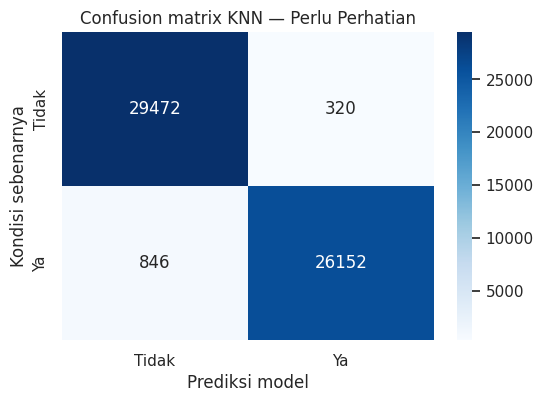

In [ ]:
# =========================================================
# 5. EVALUASI
# =========================================================
akurasi = accuracy_score(y_test, pred_knn)
recall  = recall_score(y_test, pred_knn)
f1      = f1_score(y_test, pred_knn)

print(f"Accuracy : {akurasi:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nLaporan lengkap:")
print(classification_report(
    y_test,
    pred_knn,
    target_names=["Tidak perlu", "Perlu perhatian"],
    zero_division=0,
))

# Confusion matrix
cm = confusion_matrix(y_test, pred_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Tidak", "Ya"],
    yticklabels=["Tidak", "Ya"],
)
plt.title("Confusion matrix KNN — Perlu Perhatian")
plt.xlabel("Prediksi model")
plt.ylabel("Kondisi sebenarnya")
plt.show()

In [ ]:
# =========================================================
# 6. MELIHAT TETANGGA TERDEKAT DARI SATU GURU
# =========================================================
nomor_contoh = 0
contoh = X_test.iloc[[nomor_contoh]]

scaler = model_knn.named_steps["scale"]
knn    = model_knn.named_steps["knn"]

contoh_scaled = scaler.transform(contoh)
jarak, indeks = knn.kneighbors(contoh_scaled, n_neighbors=7)

tetangga = X_train.iloc[indeks[0]].copy()
tetangga["jarak_setelah_scaling"] = np.round(jarak[0], 3)
tetangga["Perlu Perhatian"] = y_train.iloc[indeks[0]].to_numpy()

print("Guru yang diprediksi:")
display(contoh)
print("Tetangga terdekat:")
display(tetangga)

Guru yang diprediksi:


,ACH,AIN,AKC,APC,APK,BCP,CAF
11984,45.5123,47.6043,57.8077,36.9082,62.4764,65.3948,47.7321


Tetangga terdekat:


,ACH,AIN,AKC,APC,APK,BCP,CAF,jarak_setelah_scaling,Perlu Perhatian
141307,45.5123,47.6043,57.8077,36.9082,62.4764,63.3661,47.7321,0.129,1
32335,45.5123,47.6043,57.8077,36.9082,62.4764,63.3661,47.7321,0.129,1
149074,45.5123,47.6043,57.8077,36.9082,62.4764,63.3661,47.7321,0.129,1
16506,45.5123,47.6043,57.8077,36.9082,62.4764,67.7617,47.7321,0.150,1
168124,45.5123,47.6043,60.9100,36.9082,62.4764,67.7617,47.7321,0.254,1
11158,45.5123,45.8269,57.8077,37.0048,60.4916,65.3948,44.6364,0.306,1
74928,45.5123,47.6043,57.8077,36.9082,62.4764,65.3948,52.4117,0.319,1


,k,accuracy,recall
0,1,0.985,0.979
1,3,0.983,0.975
2,5,0.981,0.972
3,7,0.979,0.969
4,9,0.979,0.967
5,11,0.978,0.966
6,15,0.976,0.962
7,21,0.974,0.960


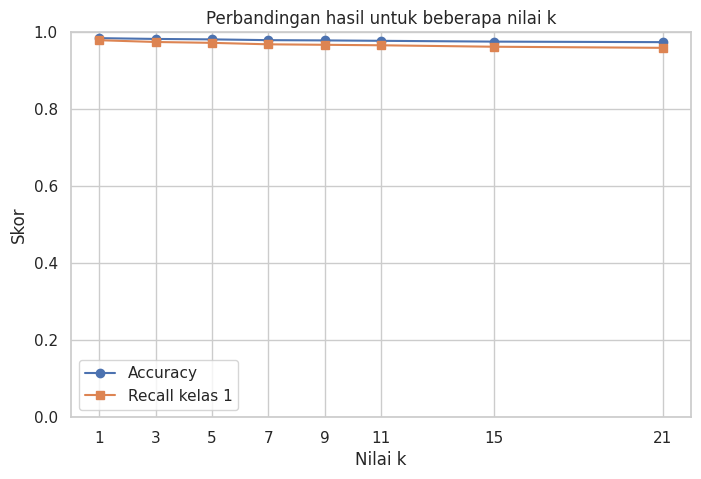

In [ ]:
# =========================================================
# 7. EKSPERIMEN NILAI k
# =========================================================
hasil_k = []
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    hasil_k.append({
        "k": k,
        "accuracy": accuracy_score(y_test, pred),
        "recall": recall_score(y_test, pred, zero_division=0),
    })

hasil_k = pd.DataFrame(hasil_k)
display(hasil_k.round(3))

plt.figure(figsize=(8, 5))
plt.plot(hasil_k["k"], hasil_k["accuracy"], marker="o", label="Accuracy")
plt.plot(hasil_k["k"], hasil_k["recall"],   marker="s", label="Recall kelas 1")
plt.xticks(hasil_k["k"])
plt.ylim(0, 1)
plt.xlabel("Nilai k")
plt.ylabel("Skor")
plt.title("Perbandingan hasil untuk beberapa nilai k")
plt.legend()
plt.show()

In [ ]:
# =========================================================
# 8. MEMPREDIKSI KASUS BARU
# =========================================================
kasus_baru = pd.DataFrame({
    "ACH": [55.0, 85.0],
    "AIN": [45.0, 90.0],
    "AKC": [60.0, 95.0],
    "APC": [40.0, 80.0],
    "APK": [50.0, 85.0],
    "BCP": [55.0, 90.0],
    "CAF": [50.0, 95.0],
})

prediksi_baru = model_knn.predict(kasus_baru)
peluang_baru  = model_knn.predict_proba(kasus_baru)[:, 1]

hasil_baru = kasus_baru.copy()
hasil_baru["prediksi_perlu_perhatian"] = prediksi_baru
hasil_baru["proporsi_tetangga_kelas_1"] = np.round(peluang_baru, 3)
display(hasil_baru)

,ACH,AIN,AKC,APC,APK,BCP,CAF,prediksi_perlu_perhatian,proporsi_tetangga_kelas_1
0,55.0,45.0,60.0,40.0,50.0,55.0,50.0,1,1.0
1,85.0,90.0,95.0,80.0,85.0,90.0,95.0,0,0.0


### **Untuk Visualisasi** **teks tebal**

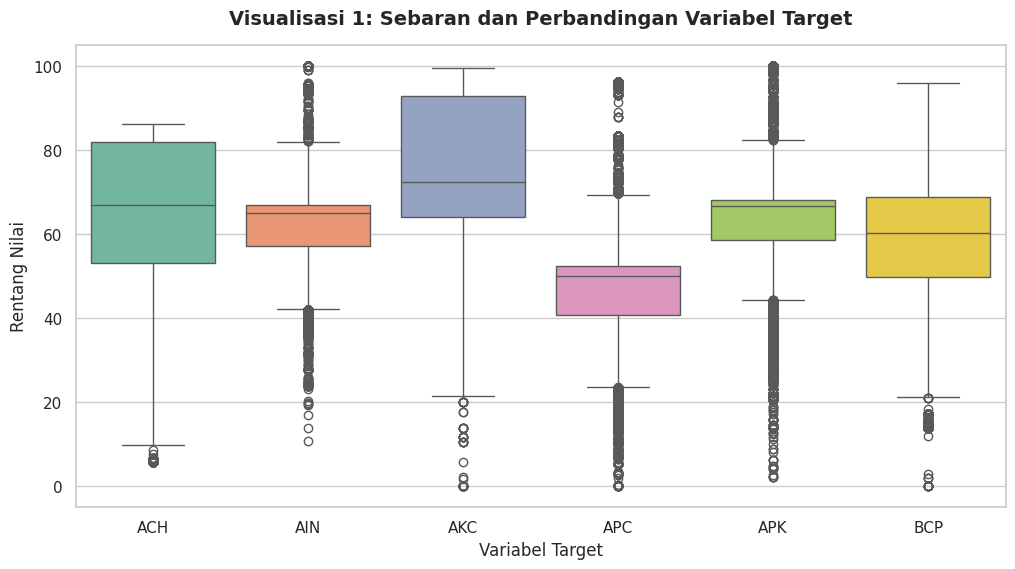

In [ ]:
# --- VISUALISASI 1: Boxplot Perbandingan Variabel Target ---
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[['ACH', 'AIN', 'AKC', 'APC', 'APK', 'BCP']], palette="Set2")
plt.title("Visualisasi 1: Sebaran dan Perbandingan Variabel Target", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Variabel Target", fontsize=12)
plt.ylabel("Rentang Nilai", fontsize=12)
plt.show()

/tmp/ipykernel_4832/551699166.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x='Korelasi', y='Variabel', data=correlations_sorted, palette="viridis")


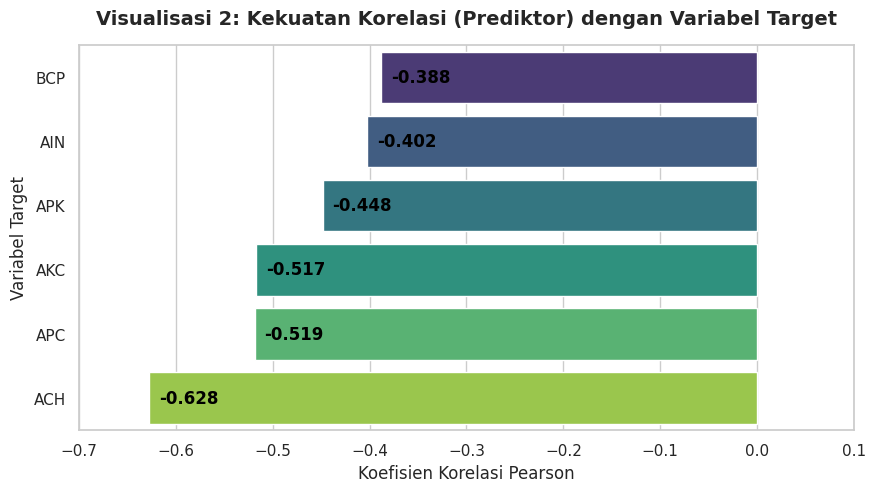

In [ ]:
# --- VISUALISASI 2: Bar Chart Kekuatan Korelasi CAF ---
correlations_sorted = correlations.sort_values(ascending=False).reset_index()
correlations_sorted.columns = ['Variabel', 'Korelasi']

plt.figure(figsize=(10, 5))
barplot = sns.barplot(x='Korelasi', y='Variabel', data=correlations_sorted, palette="viridis")

# Menambahkan label nilai di ujung bar
for index, row in correlations_sorted.iterrows():
    barplot.text(row['Korelasi'] + 0.01, index, f"{row['Korelasi']:.3f}",
                 color='black', ha="left", va="center", fontweight='bold')

plt.xlim(-0.7, 0.1)
plt.title("Visualisasi 2: Kekuatan Korelasi (Prediktor) dengan Variabel Target", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Koefisien Korelasi Pearson", fontsize=12)
plt.ylabel("Variabel Target", fontsize=12)
plt.show()

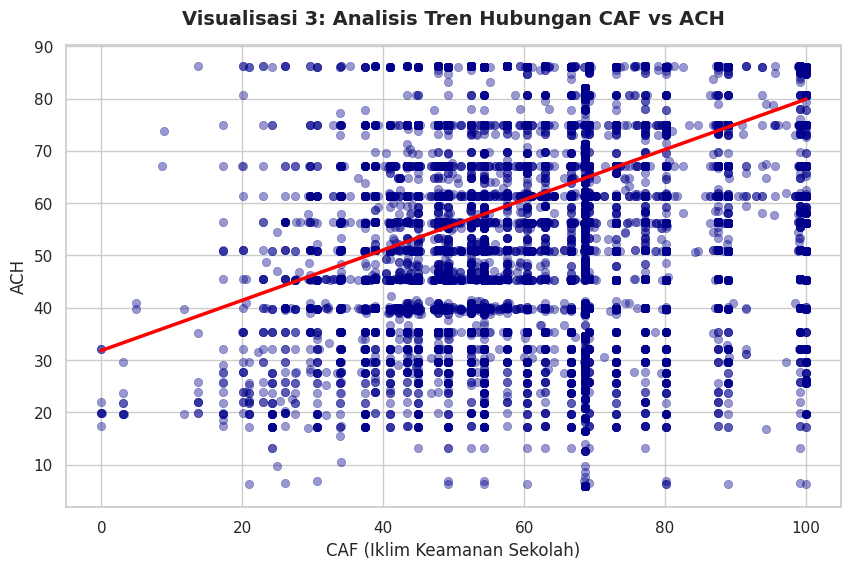

In [ ]:
# --- VISUALISASI 3: Scatter Plot Terfokus CAF vs ACH ---
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='CAF', y='ACH', alpha=0.4, color='darkblue', edgecolor=None)
sns.regplot(data=df, x='CAF', y='ACH', scatter=False, color='red', line_kws={'linewidth': 2.5})

plt.title("Visualisasi 3: Analisis Tren Hubungan CAF vs ACH", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("CAF (Iklim Keamanan Sekolah)", fontsize=12)
plt.ylabel("ACH", fontsize=12)
plt.show()

### **LAPORAN INTERPRETASI HASIL EKSPLORASI DATA (EDA)**

#### **1. Ringkasan Temuan Awal**
* Berdasarkan analisis terhadap dataset bersih **Asesmen Guru** yang memiliki skala masif sebanyak **283.948 observasi**, ditemukan bahwa rata-rata umum kompetensi guru berada pada kisaran **50.15 hingga 75.43**.
* Melalui pembuatan kriteria target baru **"Perlu Perhatian"** (guru dengan rata-rata nilai di bawah 60 atau memiliki setidaknya satu pilar nilai kompetensi di bawah 40), diperoleh data bahwa sebanyak **134.988 guru (47.5%)** masuk ke dalam kategori **"Perlu Perhatian" (Ya)**, sedangkan **148.960 guru (52.5%)** masuk ke dalam kategori **"Tidak"**.

---

#### **2. Pola atau Karakteristik Penting yang Ditemukan**
* **Hubungan Negatif Kuat dengan Status Kelayakan**: Variabel target buatan `Perlu Perhatian` menunjukkan korelasi negatif yang kuat dengan semua pilar kompetensi individu. Korelasi negatif terkuat ada pada **ACH (Pencapaian)** sebesar **-0.628**, diikuti oleh **APC** (**-0.519**) dan **AKC** (**-0.517**). Hal ini menunjukkan bahwa penurunan pada pilar-pilar ini sangat sensitif dalam menentukan apakah seorang guru memerlukan perhatian khusus.
* **Karakteristik Sebaran (Histogram & Boxplot)**:
  * Pilar **AKC** memiliki nilai rata-rata tertinggi (**75.43**), namun memiliki sebaran ekor kiri yang panjang dengan nilai minimum menyentuh 0.
  * Pilar **APC** memiliki performa terendah dengan rata-rata hanya **50.15** dan median **50.14**, menjadikannya pilar kompetensi yang paling kritis untuk diintervensi secara nasional.
  * Variabel iklim sekolah (`CAF`) memiliki rata-rata **68.70** dengan pola distribusi yang cukup terpusat di sekitar median.

---

#### **3. Masalah atau Keterbatasan Dataset**
* **Tingginya Nilai Kosong (Missing Values) Awal**: Sebelum dibersihkan, beberapa pilar seperti `AIN`, `APC`, `APK`, dan `CAF` memiliki data kosong yang cukup masif (~100.000 baris kosong). Meskipun telah diatasi dengan imputasi nilai rata-rata (*mean imputation*), hal ini dapat memicu konsentrasi data yang terlalu padat di nilai rata-rata (mempersempit variansi asli).
* **Ketiadaan Fitur Demografis**: Tidak adanya data pendukung seperti lokasi sekolah, masa kerja guru, tingkat pendidikan, maupun subjek ajar membatasi analisis kontekstual yang lebih mendalam.

---

#### **4. Kelayakan Dataset untuk Pemodelan (Phase 2)**
* **Sangat Layak**: Dataset ini memiliki volume yang sangat besar (lebih dari 280 ribu baris) setelah pembersihan, menjadikannya sangat kokoh untuk melatih model machine learning tanpa risiko kekurangan sampel (*underfitting*).
* **Representasi Kelas Seimbang**: Rasio kelas target `Perlu Perhatian` mendekati seimbang (52.5% vs 47.5%), sehingga model tidak akan bias ke salah satu kelas dominan saat proses pelatihan.

---

#### **5. Jenis Pendekatan yang Direncanakan**
* **Pendekatan Klasifikasi (Utama)**: Menggunakan algoritma klasifikasi seperti **K-Nearest Neighbors (KNN)** untuk memprediksi secara biner apakah seorang guru termasuk kategori *Perlu Perhatian* (1) atau *Tidak* (0) berdasarkan profil kompetensi mereka. Uji coba awal menggunakan KNN ($k=7$) menghasilkan akurasi yang sangat luar biasa tinggi sebesar **97.9%** dengan nilai Recall **96.9%**.
* **Pendekatan Regresi (Alternatif)**: Memodelkan nilai indeks kompetensi tertentu (misal: memprediksi nilai `ACH` atau `APC`) secara langsung menggunakan algoritma regresi berdasarkan pilar lainnya serta indeks lingkungan sekolah (`CAF`).